## Add hexapod motions to the mount plots

Craig Lage  04-Jun-25

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lsst.daf.butler import Butler
from astropy.time import Time, TimeDelta
from lsst.summit.utils.efdUtils import makeEfdClient, getEfdData
from lsst.summit.utils.simonyi.mountAnalysis import calculateMountErrors, plotMountErrors, \
        getAltAzOverPeriod, getAzElRotHexDataForExposure
from lsst.summit.utils.butlerUtils import getExpRecordFromDataId, makeDefaultButler

In [2]:
client = makeEfdClient()
butler = makeDefaultButler("LSSTCam", embargo=False)

MountErrors(azRms=8.205929325690295, elRms=6.438206813171698, rotRms=5.146496535870445, camHexRms=0.018953542892558368, m2HexRms=0.007463404961787636, imageAzRms=5.538127647242637, imageElRms=6.438206813171698, imageRotRms=0.21208281408169016, imageImpactRms=8.495102051509113, residualFiltering=False, nReplacedAz=0, nReplacedEl=0)
8.495102051509113


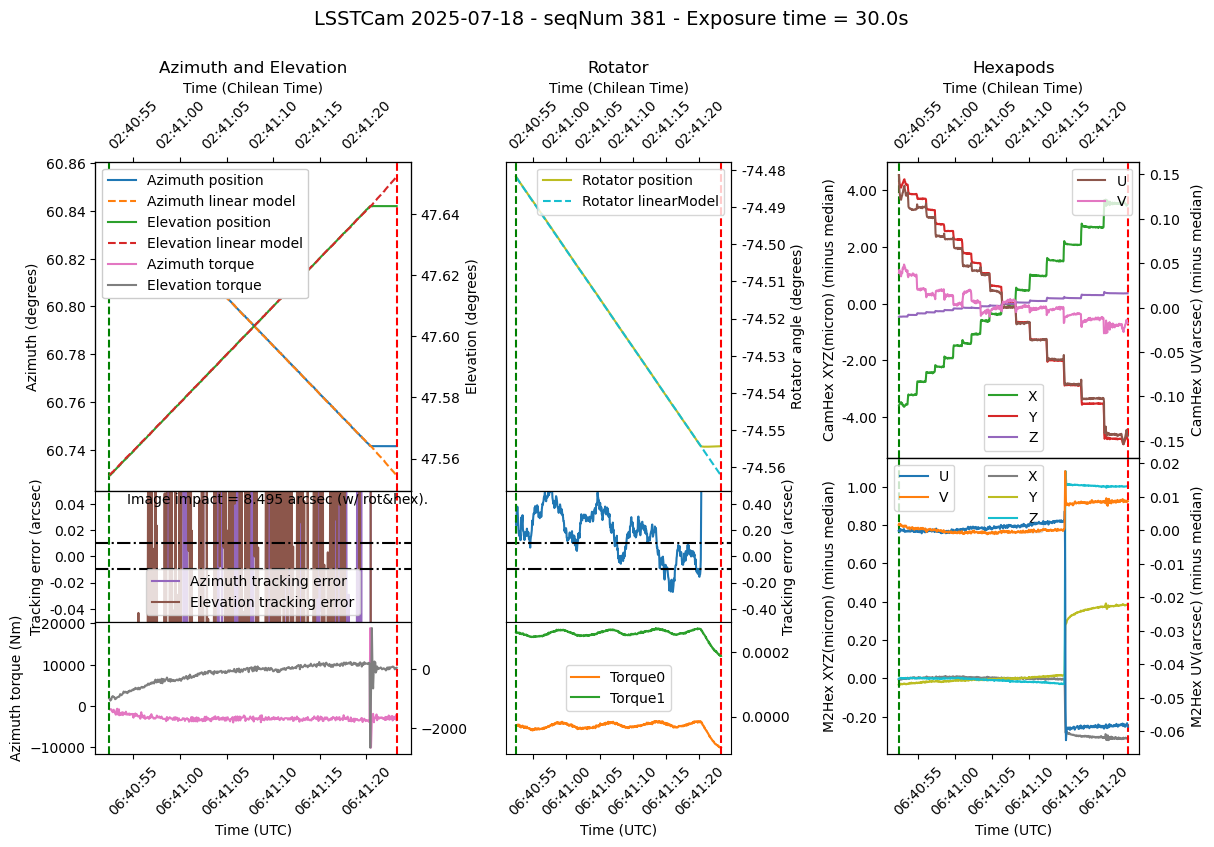

In [5]:
%matplotlib inline
expId = 2025071800381
dataId = {'exposure':expId, 'instrument':'LSSTCam'}
expRecord = getExpRecordFromDataId(butler, dataId)
(mountErrors, mountData) = calculateMountErrors(expRecord, client)
print(mountErrors)
print(mountErrors.imageImpactRms)
saveFilename = f"/home/c/cslage/claude/test_summit_utils/plots/Mount_Plot_Hex_{expId}.png"
plotMountErrors(mountData, mountErrors, saveFilename=saveFilename)
